# Cafe Sales Data Preprocessing

## Objective

The objective of this assignment is to preprocess the Cafe Sales dataset by identifying data quality issues and applying suitable preprocessing techniques. The preprocessing steps include handling missing values, detecting and handling outliers, encoding categorical variables, feature scaling, feature engineering, correlation analysis, and preparing the dataset for further machine learning tasks.

## 1. Loading the Dataset

The dataset is loaded into a Pandas DataFrame using the `read_csv()` function. This allows the dataset to be accessed and manipulated using Python.

In [ ]:
import pandas as pd

df = pd.read_csv("cafe_sales.csv")
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 2. Data Inspection

The dataset is inspected to understand its structure. Information such as the number of rows and columns, data types, missing values, and sample records is displayed to gain an overview of the dataset before preprocessing.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [ ]:
print("Rows, Columns:", df.shape)

Rows, Columns: (10000, 8)


In [ ]:
print(df.dtypes)

Transaction ID      object
Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object


In [ ]:
print(df.isnull().sum())

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


## 3. Duplicate Detection

The dataset is checked for duplicate records using the `duplicated()` function. Duplicate records, if found, would be removed to improve data quality.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [ ]:
df.tail()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07


In [ ]:
df.sample(5)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
1033,TXN_9218683,Cake,2,3.0,6.0,Digital Wallet,In-store,ERROR
2330,TXN_3849488,Salad,UNKNOWN,UNKNOWN,5.0,NaN,In-store,2023-03-01
3971,TXN_5612022,Cookie,5,1.0,5.0,Digital Wallet,ERROR,2023-09-27
8804,TXN_4204491,Smoothie,2,4.0,8.0,Digital Wallet,NaN,2023-04-25
8612,TXN_1993675,Cookie,3,1.0,3.0,Cash,Takeaway,2023-01-09


In [ ]:
df.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


## 4. Handling Missing Values

Invalid entries such as "ERROR" and "UNKNOWN" are replaced with missing values (`NaN`). Numerical columns are filled using the median, while categorical columns are filled using the mode. Rows with missing transaction dates are removed because the date information is required for feature engineering.

In [ ]:
print("ERROR values:")
print((df == "ERROR").sum())

print("\nUNKNOWN values:")
print((df == "UNKNOWN").sum())

ERROR values:
Transaction ID        0
Item                292
Quantity            170
Price Per Unit      190
Total Spent         164
Payment Method      306
Location            358
Transaction Date    142
dtype: int64

UNKNOWN values:
Transaction ID        0
Item                344
Quantity            171
Price Per Unit      164
Total Spent         165
Payment Method      293
Location            338
Transaction Date    159
dtype: int64


In [ ]:
import numpy as np

df.replace(["ERROR", "UNKNOWN"], np.nan, inplace=True)

In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Item,969
Quantity,479
Price Per Unit,533
Total Spent,502
Payment Method,3178
Location,3961
Transaction Date,460


In [ ]:
numeric_columns = ["Quantity", "Price Per Unit", "Total Spent"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [ ]:
print("Median Quantity:", df["Quantity"].median())
print("Median Price:", df["Price Per Unit"].median())
print("Median Total:", df["Total Spent"].median())

print("\nMost common Item:")
print(df["Item"].mode())

print("\nMost common Payment Method:")
print(df["Payment Method"].mode())

print("\nMost common Location:")
print(df["Location"].mode())

Median Quantity: 3.0
Median Price: 3.0
Median Total: 8.0

Most common Item:
0    Juice
Name: Item, dtype: object

Most common Payment Method:
0    Digital Wallet
Name: Payment Method, dtype: object

Most common Location:
0    Takeaway
Name: Location, dtype: object


In [ ]:
# Numeric columns
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Price Per Unit"] = df["Price Per Unit"].fillna(df["Price Per Unit"].median())
df["Total Spent"] = df["Total Spent"].fillna(df["Total Spent"].median())

# Categorical columns
df["Item"] = df["Item"].fillna(df["Item"].mode()[0])
df["Payment Method"] = df["Payment Method"].fillna(df["Payment Method"].mode()[0])
df["Location"] = df["Location"].fillna(df["Location"].mode()[0])

In [ ]:
df = df.dropna(subset=["Transaction Date"])

In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9540 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    9540 non-null   object 
 1   Item              9540 non-null   object 
 2   Quantity          9540 non-null   float64
 3   Price Per Unit    9540 non-null   float64
 4   Total Spent       9540 non-null   float64
 5   Payment Method    9540 non-null   object 
 6   Location          9540 non-null   object 
 7   Transaction Date  9540 non-null   object 
dtypes: float64(3), object(5)
memory usage: 670.8+ KB


In [ ]:
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9540 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9540 non-null   object        
 1   Item              9540 non-null   object        
 2   Quantity          9540 non-null   float64       
 3   Price Per Unit    9540 non-null   float64       
 4   Total Spent       9540 non-null   float64       
 5   Payment Method    9540 non-null   object        
 6   Location          9540 non-null   object        
 7   Transaction Date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 670.8+ KB


## 5. Outlier Detection and Handling

Outliers are detected using the Interquartile Range (IQR) method and visualized with box plots. The detected outliers are inspected before making any decision. Records containing inconsistent values where Quantity × Price Per Unit did not equal Total Spent are removed from the dataset.

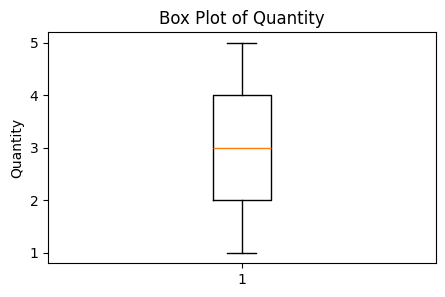

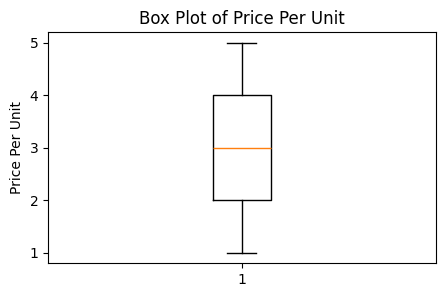

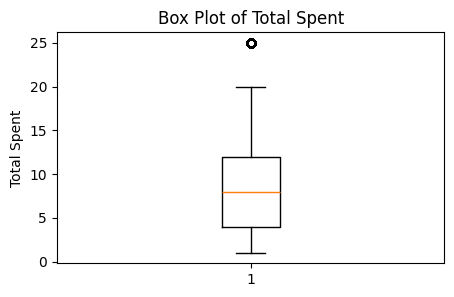

In [ ]:
import matplotlib.pyplot as plt

numeric_cols = ["Quantity", "Price Per Unit", "Total Spent"]

for col in numeric_cols:
    plt.figure(figsize=(5, 3))
    plt.boxplot(df[col])
    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)
    plt.show()

In [ ]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\nColumn: {col}")
    print(f"Q1 = {Q1}")
    print(f"Q3 = {Q3}")
    print(f"IQR = {IQR}")
    print(f"Lower Bound = {lower_bound}")
    print(f"Upper Bound = {upper_bound}")
    print(f"Number of Outliers = {len(outliers)}")


Column: Quantity
Q1 = 2.0
Q3 = 4.0
IQR = 2.0
Lower Bound = -1.0
Upper Bound = 7.0
Number of Outliers = 0

Column: Price Per Unit
Q1 = 2.0
Q3 = 4.0
IQR = 2.0
Lower Bound = -1.0
Upper Bound = 7.0
Number of Outliers = 0

Column: Total Spent
Q1 = 4.0
Q3 = 12.0
IQR = 8.0
Lower Bound = -8.0
Upper Bound = 24.0
Number of Outliers = 250


In [ ]:
Q1 = df["Total Spent"].quantile(0.25)
Q3 = df["Total Spent"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[df["Total Spent"] > upper_bound]

outliers.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
10,TXN_2548360,Salad,5.0,5.0,25.0,Cash,Takeaway,2023-11-07
51,TXN_6342161,Salad,5.0,5.0,25.0,Digital Wallet,Takeaway,2023-01-08
52,TXN_8914892,Juice,5.0,5.0,25.0,Digital Wallet,Takeaway,2023-03-15
96,TXN_5220895,Salad,5.0,5.0,25.0,Cash,In-store,2023-06-10
100,TXN_9517146,Juice,5.0,5.0,25.0,Cash,Takeaway,2023-10-30
150,TXN_8687151,Salad,5.0,5.0,25.0,Cash,Takeaway,2023-06-10
157,TXN_4283157,Salad,5.0,5.0,25.0,Digital Wallet,In-store,2023-11-25
177,TXN_1896955,Salad,3.0,5.0,25.0,Digital Wallet,In-store,2023-09-23
214,TXN_8693704,Salad,3.0,5.0,25.0,Cash,In-store,2023-05-04
330,TXN_5523450,Salad,5.0,5.0,25.0,Credit Card,Takeaway,2023-07-02


In [ ]:
outliers[outliers["Quantity"] * outliers["Price Per Unit"] != outliers["Total Spent"]]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
177,TXN_1896955,Salad,3.0,5.0,25.0,Digital Wallet,In-store,2023-09-23
214,TXN_8693704,Salad,3.0,5.0,25.0,Cash,In-store,2023-05-04
777,TXN_7109358,Salad,3.0,5.0,25.0,Digital Wallet,Takeaway,2023-05-02
874,TXN_9392028,Salad,5.0,3.0,25.0,Credit Card,In-store,2023-01-13
1330,TXN_4250492,Salad,5.0,3.0,25.0,Digital Wallet,Takeaway,2023-09-29
1479,TXN_5191642,Salad,3.0,5.0,25.0,Cash,Takeaway,2023-04-15
2189,TXN_5932169,Salad,5.0,3.0,25.0,Credit Card,Takeaway,2023-11-06
2265,TXN_7397665,Salad,5.0,3.0,25.0,Credit Card,Takeaway,2023-11-11
2532,TXN_6378158,Salad,5.0,3.0,25.0,Credit Card,In-store,2023-06-17
3102,TXN_3113823,Salad,5.0,3.0,25.0,Digital Wallet,In-store,2023-03-01


In [ ]:
df = df[df["Quantity"] * df["Price Per Unit"] == df["Total Spent"]]

In [ ]:
df[df["Quantity"] * df["Price Per Unit"] != df["Total Spent"]]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date


In [ ]:
categorical_cols = ["Item", "Payment Method", "Location"]

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].unique())


Item
['Coffee' 'Cake' 'Salad' 'Smoothie' 'Juice' 'Sandwich' 'Cookie' 'Tea']

Payment Method
['Credit Card' 'Cash' 'Digital Wallet']

Location
['Takeaway' 'In-store']


## 6. Encoding Categorical Variables

Categorical variables such as Item, Payment Method, and Location are converted into numerical values using One-Hot Encoding. This encoding method is appropriate because the categories do not have any natural ordering.

####One Hot Encoding

In [ ]:
df_encoded = pd.get_dummies(
    df,
    columns=["Item", "Payment Method", "Location"],
    dtype=int
)

In [ ]:
df_encoded.head()

,Transaction ID,Quantity,Price Per Unit,Total Spent,Transaction Date,Item_Cake,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,Item_Sandwich,Item_Smoothie,Item_Tea,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_In-store,Location_Takeaway
0,TXN_1961373,2.0,2.0,4.0,2023-09-08,0,1,0,0,0,0,0,0,0,1,0,0,1
1,TXN_4977031,4.0,3.0,12.0,2023-05-16,1,0,0,0,0,0,0,0,1,0,0,1,0
3,TXN_7034554,2.0,5.0,10.0,2023-04-27,0,0,0,0,1,0,0,0,0,0,1,0,1
4,TXN_3160411,2.0,2.0,4.0,2023-06-11,0,1,0,0,0,0,0,0,0,0,1,1,0
5,TXN_2602893,5.0,4.0,20.0,2023-03-31,0,0,0,0,0,0,1,0,0,1,0,0,1


####Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_df = df.copy()

encoder = LabelEncoder()

label_df["Item"] = encoder.fit_transform(label_df["Item"])
label_df["Payment Method"] = encoder.fit_transform(label_df["Payment Method"])
label_df["Location"] = encoder.fit_transform(label_df["Location"])

label_df[["Item", "Payment Method", "Location"]].head()

,Item,Payment Method,Location
0,1,1,1
1,0,0,0
3,4,2,1
4,1,2,0
5,6,1,1


Label Encoding was demonstrated. One-Hot Encoding was selected for the final dataset because the categorical variables are nominal (no natural ordering).

## 7. Feature Scaling

Min-Max Normalization is applied to the numerical features so that all values are scaled between 0 and 1. Feature scaling ensures that variables with larger numerical values do not dominate those with smaller values.

In [ ]:
numeric_cols = ["Quantity", "Price Per Unit", "Total Spent"]

####Min Max Scaling

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_encoded[numeric_cols] = scaler.fit_transform(df_encoded[numeric_cols])

In [ ]:
df_encoded[numeric_cols].head()

,Quantity,Price Per Unit,Total Spent
0,0.25,0.25,0.125000
1,0.75,0.50,0.458333
3,0.25,1.00,0.375000
4,0.25,0.25,0.125000
5,1.00,0.75,0.791667


###Z score Normalization

In [ ]:
from sklearn.preprocessing import StandardScaler

standard_df = df_encoded.copy()

scaler = StandardScaler()

standard_df[["Quantity", "Price Per Unit", "Total Spent"]] = scaler.fit_transform(
    standard_df[["Quantity", "Price Per Unit", "Total Spent"]]
)

standard_df[["Quantity", "Price Per Unit", "Total Spent"]].head()

,Quantity,Price Per Unit,Total Spent
0,-0.722236,-0.752071,-0.827479
1,0.697247,0.037423,0.519381
3,-0.722236,1.616411,0.182666
4,-0.722236,-0.752071,-0.827479
5,1.406989,0.826917,1.866241


Standardization was implemented for demonstration purposes. Min-Max Scaling was used in the final preprocessed dataset.

## 8. Correlation Analysis

A correlation matrix and heatmap are generated to examine relationships between numerical variables. Correlation analysis helps identify how strongly different variables are related.

Values range from:

-1   to   +1
+1 → perfect positive relationship.
0 → no linear relationship.
−1 → perfect negative relationship.

In [ ]:
correlation = df_encoded.select_dtypes(include=["number"]).corr()

correlation

,Quantity,Price Per Unit,Total Spent,Item_Cake,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,Item_Sandwich,Item_Smoothie,Item_Tea,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_In-store,Location_Takeaway
Quantity,1.000000,0.002934,0.705110,0.002184,0.013770,-0.007867,-0.010295,0.003019,-0.007381,0.008164,0.001221,0.009019,-0.007811,-0.000978,0.002633,-0.002633
Price Per Unit,0.002934,1.000000,0.644023,0.013758,-0.274766,-0.530771,0.009511,0.576256,0.293571,0.287742,-0.393120,0.016816,0.019940,-0.030936,0.010086,-0.010086
Total Spent,0.705110,0.644023,1.000000,0.010083,-0.170600,-0.343719,-0.000667,0.374085,0.181595,0.192600,-0.252839,0.015483,0.006174,-0.018203,0.009126,-0.009126
Item_Cake,0.002184,0.013758,0.010083,1.000000,-0.134316,-0.126582,-0.194874,-0.131066,-0.130520,-0.127928,-0.126025,0.016144,-0.006195,-0.008322,-0.016955,0.016955
Item_Coffee,0.013770,-0.274766,-0.170600,-0.134316,1.000000,-0.125791,-0.193657,-0.130247,-0.129704,-0.127129,-0.125237,-0.026631,-0.020704,0.039817,-0.021602,0.021602
Item_Cookie,-0.007867,-0.530771,-0.343719,-0.126582,-0.125791,1.000000,-0.182505,-0.122747,-0.122235,-0.119808,-0.118026,0.000150,0.004681,-0.004075,-0.002513,0.002513
Item_Juice,-0.010295,0.009511,-0.000667,-0.194874,-0.193657,-0.182505,1.000000,-0.188970,-0.188183,-0.184447,-0.181702,-0.000448,0.013677,-0.011164,0.013971,-0.013971
Item_Salad,0.003019,0.576256,0.374085,-0.131066,-0.130247,-0.122747,-0.188970,1.000000,-0.126565,-0.124052,-0.122207,0.022782,0.021523,-0.037279,0.010491,-0.010491
Item_Sandwich,-0.007381,0.293571,0.181595,-0.130520,-0.129704,-0.122235,-0.188183,-0.126565,1.000000,-0.123536,-0.121697,-0.001904,-0.003911,0.004897,0.022124,-0.022124
Item_Smoothie,0.008164,0.287742,0.192600,-0.127928,-0.127129,-0.119808,-0.184447,-0.124052,-0.123536,1.000000,-0.119281,-0.009786,0.003829,0.004981,-0.007611,0.007611


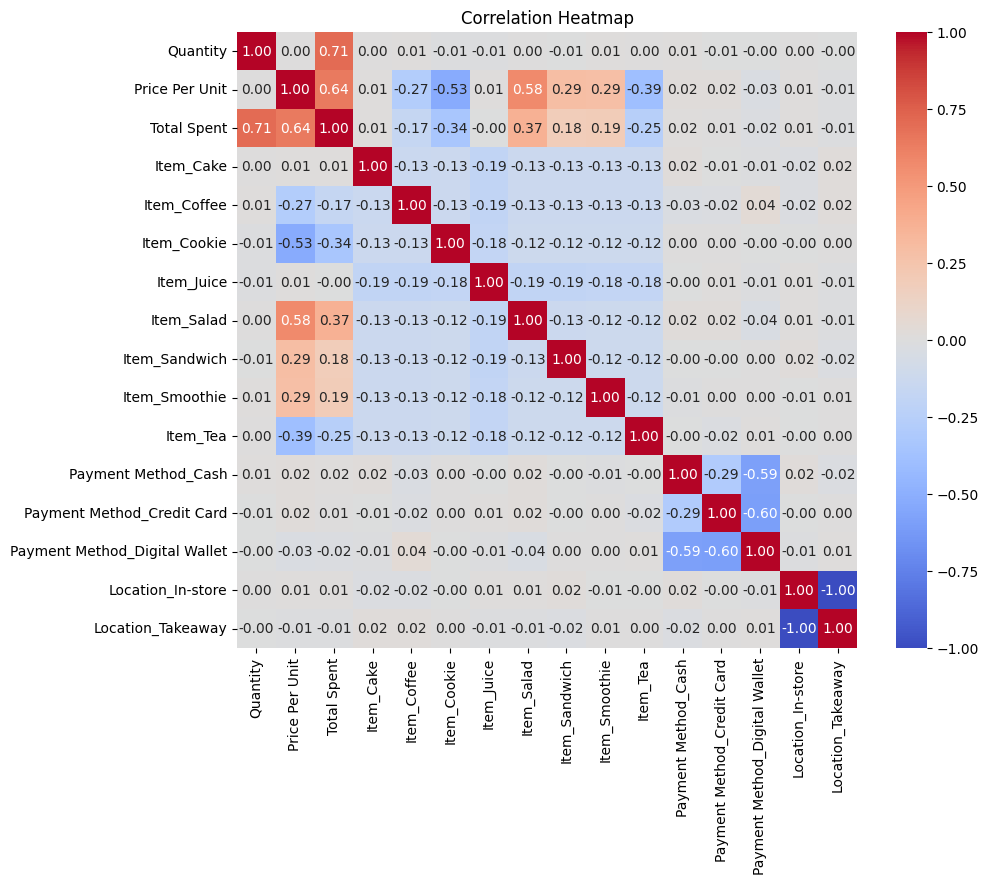

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

## 9. Feature Engineering

Additional features such as Year, Month, Day, and Day of Week are extracted from the Transaction Date column. These new features may provide useful information for future analysis and machine learning models.

In [ ]:
df_encoded["Year"] = df_encoded["Transaction Date"].dt.year
df_encoded["Month"] = df_encoded["Transaction Date"].dt.month
df_encoded["Day"] = df_encoded["Transaction Date"].dt.day
df_encoded["DayOfWeek"] = df_encoded["Transaction Date"].dt.day_name()

In [ ]:
df_encoded.head()

,Transaction ID,Quantity,Price Per Unit,Total Spent,Transaction Date,Item_Cake,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,...,Item_Tea,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_In-store,Location_Takeaway,Year,Month,Day,DayOfWeek
0,TXN_1961373,0.25,0.25,0.125000,2023-09-08,0,1,0,0,0,...,0,0,1,0,0,1,2023,9,8,Friday
1,TXN_4977031,0.75,0.50,0.458333,2023-05-16,1,0,0,0,0,...,0,1,0,0,1,0,2023,5,16,Tuesday
3,TXN_7034554,0.25,1.00,0.375000,2023-04-27,0,0,0,0,1,...,0,0,0,1,0,1,2023,4,27,Thursday
4,TXN_3160411,0.25,0.25,0.125000,2023-06-11,0,1,0,0,0,...,0,0,0,1,1,0,2023,6,11,Sunday
5,TXN_2602893,1.00,0.75,0.791667,2023-03-31,0,0,0,0,0,...,0,0,1,0,0,1,2023,3,31,Friday


In [ ]:
df_encoded = pd.get_dummies(
    df_encoded,
    columns=["DayOfWeek"],
    dtype=int
)

## 10. Feature Selection

The Transaction ID column is removed because it is only an identifier and does not contribute useful information for analysis. After extracting useful date-related features, the original Transaction Date column is also removed.

In [ ]:
df_encoded.drop("Transaction Date", axis=1, inplace=True)

In [ ]:
df_encoded.head()

,Transaction ID,Quantity,Price Per Unit,Total Spent,Item_Cake,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,Item_Sandwich,...,Year,Month,Day,DayOfWeek_Friday,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday
0,TXN_1961373,0.25,0.25,0.125000,0,1,0,0,0,0,...,2023,9,8,1,0,0,0,0,0,0
1,TXN_4977031,0.75,0.50,0.458333,1,0,0,0,0,0,...,2023,5,16,0,0,0,0,0,1,0
3,TXN_7034554,0.25,1.00,0.375000,0,0,0,0,1,0,...,2023,4,27,0,0,0,0,1,0,0
4,TXN_3160411,0.25,0.25,0.125000,0,1,0,0,0,0,...,2023,6,11,0,0,0,1,0,0,0
5,TXN_2602893,1.00,0.75,0.791667,0,0,0,0,0,0,...,2023,3,31,1,0,0,0,0,0,0


In [ ]:
df_encoded.drop("Transaction ID", axis=1, inplace=True)

In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8407 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Quantity                       8407 non-null   float64
 1   Price Per Unit                 8407 non-null   float64
 2   Total Spent                    8407 non-null   float64
 3   Item_Cake                      8407 non-null   int64  
 4   Item_Coffee                    8407 non-null   int64  
 5   Item_Cookie                    8407 non-null   int64  
 6   Item_Juice                     8407 non-null   int64  
 7   Item_Salad                     8407 non-null   int64  
 8   Item_Sandwich                  8407 non-null   int64  
 9   Item_Smoothie                  8407 non-null   int64  
 10  Item_Tea                       8407 non-null   int64  
 11  Payment Method_Cash            8407 non-null   int64  
 12  Payment Method_Credit Card     8407 non-null   int64 

## 11. Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. A random state of 42 is used to ensure that the same split is obtained every time the notebook is executed.

In [ ]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop("Total Spent", axis=1)
y = df_encoded["Total Spent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (6725, 25)
Testing features: (1682, 25)
Training target: (6725,)
Testing target: (1682,)


## 12. Data Balancing

Data balancing techniques such as Random Oversampling and SMOTE were not applied because the dataset does not contain an imbalanced target class. The dataset is not a classification problem, so these techniques are not applicable.

## 13. Data Visualization

Histograms are generated before and after preprocessing to compare the distribution of numerical features. The distributions remain similar, while the values are rescaled after Min-Max Normalization.

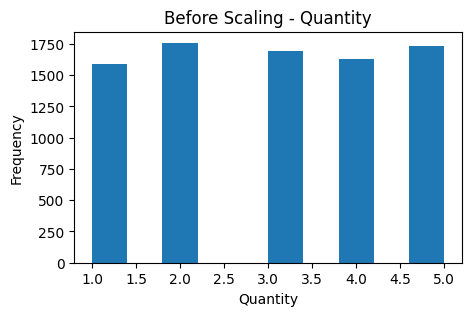

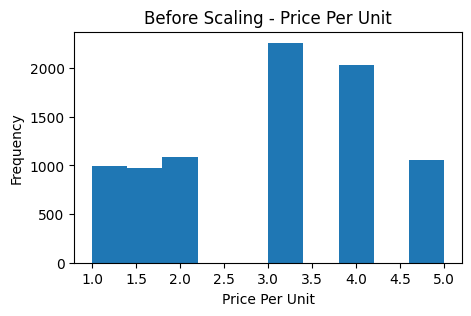

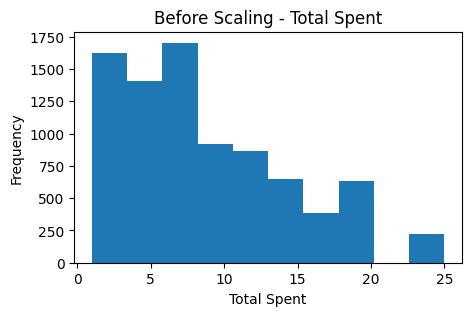

In [ ]:
import matplotlib.pyplot as plt

numeric_cols = ["Quantity", "Price Per Unit", "Total Spent"]

for col in numeric_cols:
    plt.figure(figsize=(5,3))
    plt.hist(df[col], bins=10)
    plt.title(f"Before Scaling - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

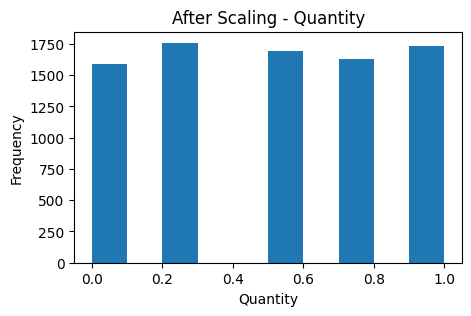

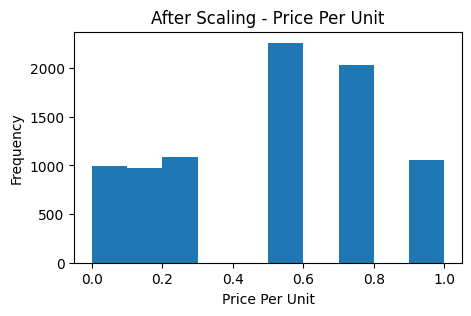

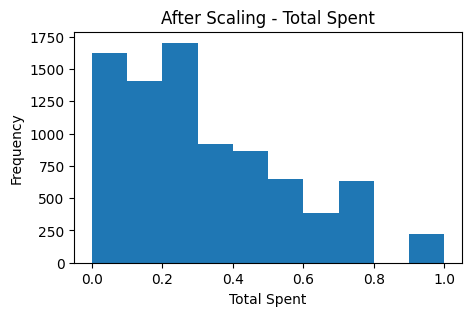

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(5,3))
    plt.hist(df_encoded[col], bins=10)
    plt.title(f"After Scaling - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

## 14. Comparison Before and After Preprocessing

| Aspect | Before Preprocessing | After Preprocessing |
|---------|----------------------|---------------------|
| Rows | 10,000 | 8,407 |
| Missing Values | Present | Handled |
| Duplicate Records | 0 | 0 |
| Categorical Variables | Original text values | One-Hot Encoded |
| Numerical Features | Original values | Min-Max Normalized |
| Data Types | Mixed | Appropriate numeric data types |
| Outliers | Present | Investigated and inconsistent records removed |

The preprocessing process improved the overall quality of the dataset by handling missing values, correcting data types, removing inconsistent records, encoding categorical variables, scaling numerical features, and creating new features from the transaction date.

## 15. Saving the Preprocessed Dataset

The cleaned and preprocessed dataset is saved as a new CSV file for future analysis and machine learning applications.

In [ ]:
df_encoded.to_csv("cafe_sales_preprocessed.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


# Conclusion

The Cafe Sales dataset was successfully preprocessed by handling missing values, removing inconsistent records, detecting outliers, encoding categorical variables, scaling numerical features, performing feature engineering, and splitting the dataset into training and testing sets. The final dataset is clean, consistent, and suitable for further data analysis and machine learning tasks.

## 16. Linear Regression Model Training and Evaluation

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
X_simple_train = X_train[["Quantity"]]
X_simple_test = X_test[["Quantity"]]

In [ ]:
simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train)

y_pred_s = simple_model.predict(X_simple_test)

In [ ]:
mae_s = mean_absolute_error(y_test, y_pred_s)
mse_s = mean_squared_error(y_test, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test, y_pred_s)

In [ ]:
print("--- Simple Linear Regression Results ---")
print(f"Mean Absolute Error (MAE): {mae_s:.4f}")
print(f"Mean Squared Error (MSE): {mse_s:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_s:.4f}")
print(f"R-squared (R2 Score): {r2_s:.4f}")

--- Simple Linear Regression Results ---
Mean Absolute Error (MAE): 0.1322
Mean Squared Error (MSE): 0.0311
Root Mean Squared Error (RMSE): 0.1763
R-squared (R2 Score): 0.5031


####Multi variable linear regression

In [ ]:
linear_reg_model = LinearRegression()

linear_reg_model.fit(X_train, y_train)

y_pred = linear_reg_model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [ ]:
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")

Mean Absolute Error (MAE): 0.0521
Mean Squared Error (MSE): 0.0054
Root Mean Squared Error (RMSE): 0.0735
R-squared (R2): 0.9135


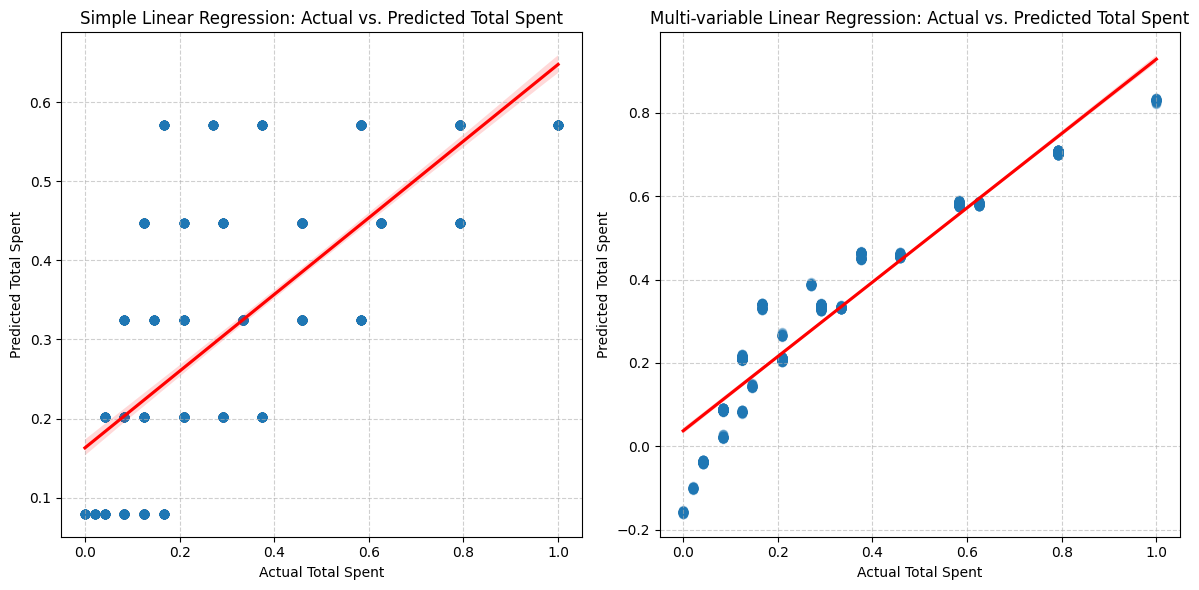

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
sns.regplot(x=y_test, y=y_pred_s, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Simple Linear Regression: Actual vs. Predicted Total Spent')
plt.xlabel('Actual Total Spent')
plt.ylabel('Predicted Total Spent')
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
sns.regplot(x=y_test, y=y_pred, scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Multi-variable Linear Regression: Actual vs. Predicted Total Spent')
plt.xlabel('Actual Total Spent')
plt.ylabel('Predicted Total Spent')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()